In [76]:
!pip install -q imbalanced-learn

In [77]:
!pip install xgboost lightgbm catboost

In [78]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder, MinMaxScaler, RobustScaler

# Classification Models
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Boosting Models
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# Evaluation Metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings('ignore')

In [85]:
dir_path = os.path.join(os.getcwd(),'air_sound_pressure_log_data.csv')
df = pd.read_csv(dir_path)  # Load your dataset here

In [86]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1339 entries, 0 to 1338
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   sample              1339 non-null   int64  
 1   dc_v                1339 non-null   float64
 2   rms                 1339 non-null   float64
 3   p2p                 1339 non-null   int64  
 4   d0                  1339 non-null   int64  
 5   level_db            1339 non-null   float64
 6   freq_hz             1339 non-null   float64
 7   freq_reliable       1339 non-null   int64  
 8   centroid_hz         1339 non-null   float64
 9   raw                 1339 non-null   int64  
 10  difference          1339 non-null   int64  
 11  pressure_kpa        1339 non-null   float64
 12  pump_on             1339 non-null   int64  
 13  delta_pressure_kpa  1337 non-null   float64
 14  delta_freq_hz       1337 non-null   float64
 15  label               1339 non-null   object 
dtypes: flo

In [87]:
df.dropna(inplace=True)  # Drop rows with missing values


In [88]:
df.drop(columns=['sample', 'dc_v', 'd0', 'pump_on', 'raw','difference', 'freq_reliable', 'delta_freq_hz'], inplace=True)  # Drop unnecessary columns

In [89]:

df.drop_duplicates(inplace=True)  # Drop duplicate rows

In [90]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1337 entries, 1 to 1338
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   rms                 1337 non-null   float64
 1   p2p                 1337 non-null   int64  
 2   level_db            1337 non-null   float64
 3   freq_hz             1337 non-null   float64
 4   centroid_hz         1337 non-null   float64
 5   pressure_kpa        1337 non-null   float64
 6   delta_pressure_kpa  1337 non-null   float64
 7   label               1337 non-null   object 
dtypes: float64(6), int64(1), object(1)
memory usage: 94.0+ KB


In [91]:
# Features and target
X = df.drop(columns=['label'])
y = df['label'].copy()

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget classes:")
print(y.value_counts())

Features shape: (1337, 7)
Target shape: (1337,)

Target classes:
label
not leakage    1147
leakage         190
Name: count, dtype: int64


In [92]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (1069, 7)
X_test: (268, 7)


Before Oversampling:
label
not leakage    917
leakage        152
Name: count, dtype: int64


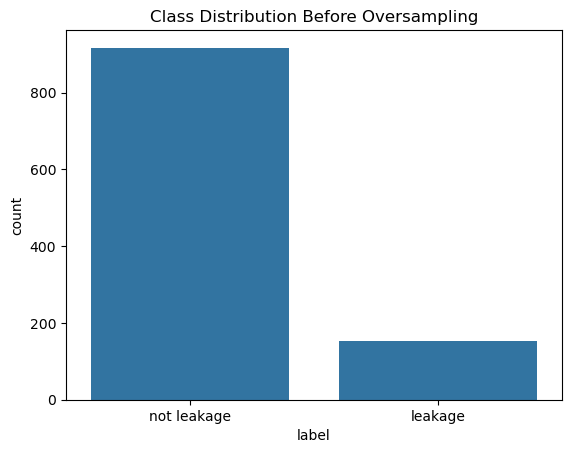

In [93]:
print("Before Oversampling:")
print(pd.Series(y_train).value_counts())

sns.countplot(x=y_train)
plt.title("Class Distribution Before Oversampling")
plt.show()

In [95]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(
    sampling_strategy='auto',
    random_state=42,
    k_neighbors=5
)

X_train_resampled, y_train_resampled =X_train,y_train

print("After Oversampling:")
print(pd.Series(y_train_resampled).value_counts())

print("\nOriginal training shape:", X_train.shape)
print("Resampled training shape:", X_train_resampled.shape)

After Oversampling:
label
not leakage    917
leakage        152
Name: count, dtype: int64

Original training shape: (1069, 7)
Resampled training shape: (1069, 7)


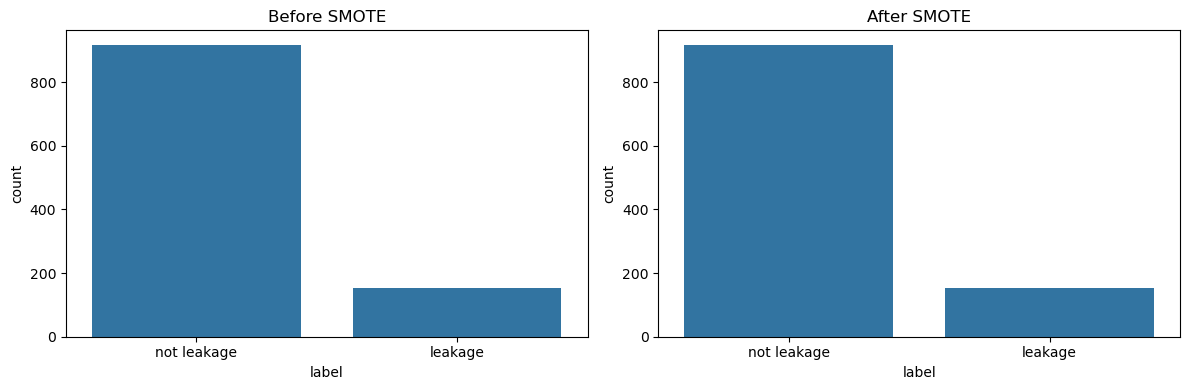

In [96]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(x=y_train, ax=axes[0])
axes[0].set_title("Before SMOTE")

sns.countplot(x=y_train_resampled, ax=axes[1])
axes[1].set_title("After SMOTE")

plt.tight_layout()
plt.show()

In [105]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_resampled)
X_test_scaled = scaler.transform(X_test)

print("Scaled training:", X_train_scaled.shape)
print("Scaled testing:", X_test_scaled.shape)

Scaled training: (1069, 7)
Scaled testing: (268, 7)


In [106]:
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train_resampled)
y_test_encoded = label_encoder.transform(y_test)

print("Class Mapping:")

for i, class_name in enumerate(label_encoder.classes_):
    print(f"{class_name} -> {i}")

Class Mapping:
leakage -> 0
not leakage -> 1


In [107]:
# ==================================
# Logistic Regression
# ==================================

lr_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

# Training
lr_model.fit(X_train_scaled, y_train_encoded)

# Predictions
lr_train_pred = lr_model.predict(X_train_scaled)
lr_test_pred = lr_model.predict(X_test_scaled)

# Evaluation
print("========== Logistic Regression ==========")

print("\nClassification Report - Testing:")
print(classification_report(
    y_test_encoded,
    lr_test_pred,
    target_names=label_encoder.classes_.astype(str)
))

print("\nConfusion Matrix - Testing:")
print(confusion_matrix(y_test_encoded, lr_test_pred))

========== Logistic Regression ==========

Classification Report - Testing:
              precision    recall  f1-score   support

     leakage       0.95      0.97      0.96        38
 not leakage       1.00      0.99      0.99       230

    accuracy                           0.99       268
   macro avg       0.97      0.98      0.98       268
weighted avg       0.99      0.99      0.99       268


Confusion Matrix - Testing:
[[ 37   1]
 [  2 228]]


In [108]:
# ==================================
# Support Vector Machine
# ==================================

svm_model = SVC(
    kernel='rbf',
    C=1.0,
    random_state=42
)

# Training
svm_model.fit(X_train_scaled, y_train_encoded)

# Predictions
svm_train_pred = svm_model.predict(X_train_scaled)
svm_test_pred = svm_model.predict(X_test_scaled)

# Evaluation
print("========== Support Vector Machine ==========")

print("\nClassification Report - Testing:")
print(classification_report(
    y_test_encoded,
    svm_test_pred,
    target_names=label_encoder.classes_.astype(str)
))

print("\nConfusion Matrix - Testing:")
print(confusion_matrix(y_test_encoded, svm_test_pred))

========== Support Vector Machine ==========

Classification Report - Testing:
              precision    recall  f1-score   support

     leakage       0.95      1.00      0.97        38
 not leakage       1.00      0.99      1.00       230

    accuracy                           0.99       268
   macro avg       0.97      1.00      0.98       268
weighted avg       0.99      0.99      0.99       268


Confusion Matrix - Testing:
[[ 38   0]
 [  2 228]]


In [109]:
import joblib
import os

# Save SVC Model
joblib.dump(svm_model, "models/svc_model.pkl")

# Save StandardScaler
joblib.dump(scaler, "models/scaler.pkl")

# Save Label Encoder
joblib.dump(label_encoder, "models/label_encoder.pkl")

print("SVC Model, Scaler and Label Encoder saved successfully!")

SVC Model, Scaler and Label Encoder saved successfully!


In [104]:
import joblib, os
os.makedirs("models", exist_ok=True)

assert svm_model.n_features_in_ == scaler.n_features_in_ == X_train.shape[1], \
    f"Mismatch: SVM {svm_model.n_features_in_}, scaler {scaler.n_features_in_}, data {X_train.shape[1]}. Re-run the SVM cell."

print("Training columns:", list(X_train.columns))
joblib.dump(svm_model, "models/svc_model.pkl")
joblib.dump(scaler, "models/scaler.pkl")
joblib.dump(label_encoder, "models/label_encoder.pkl")
print("Saved. All three match.")

Training columns: ['rms', 'p2p', 'level_db', 'freq_hz', 'centroid_hz', 'pressure_kpa', 'delta_pressure_kpa']
Saved. All three match.


In [102]:
# ==================================
# Decision Tree
# ==================================

dt_model = DecisionTreeClassifier(
    random_state=42
)

# Training
dt_model.fit(X_train_scaled, y_train_encoded)

# Predictions
dt_train_pred = dt_model.predict(X_train_scaled)
dt_test_pred = dt_model.predict(X_test_scaled)

# Evaluation
print("========== Decision Tree ==========")

print("\nClassification Report - Testing:")
print(classification_report(
    y_test_encoded,
    dt_test_pred,
    target_names=label_encoder.classes_.astype(str)
))

print("\nConfusion Matrix - Testing:")
print(confusion_matrix(y_test_encoded, dt_test_pred))

========== Decision Tree ==========

Classification Report - Testing:
              precision    recall  f1-score   support

     leakage       1.00      1.00      1.00        38
 not leakage       1.00      1.00      1.00       230

    accuracy                           1.00       268
   macro avg       1.00      1.00      1.00       268
weighted avg       1.00      1.00      1.00       268


Confusion Matrix - Testing:
[[ 38   0]
 [  0 230]]


In [68]:
# ==================================
# Random Forest
# ==================================

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# Training
rf_model.fit(X_train_scaled, y_train_encoded)

# Predictions
rf_train_pred = rf_model.predict(X_train_scaled)
rf_test_pred = rf_model.predict(X_test_scaled)

# Evaluation
print("========== Random Forest ==========")

print("\nClassification Report - Testing:")
print(classification_report(
    y_test_encoded,
    rf_test_pred,
    target_names=label_encoder.classes_.astype(str)
))

print("\nConfusion Matrix - Testing:")
print(confusion_matrix(y_test_encoded, rf_test_pred))

========== Random Forest ==========

Classification Report - Testing:
              precision    recall  f1-score   support

     leakage       1.00      1.00      1.00        38
 not leakage       1.00      1.00      1.00       230

    accuracy                           1.00       268
   macro avg       1.00      1.00      1.00       268
weighted avg       1.00      1.00      1.00       268


Confusion Matrix - Testing:
[[ 38   0]
 [  0 230]]


In [69]:
# ==================================
# XGBoost
# ==================================

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    eval_metric='logloss',
    verbosity=0
)

# Training
xgb_model.fit(X_train_scaled, y_train_encoded)

# Predictions
xgb_train_pred = xgb_model.predict(X_train_scaled)
xgb_test_pred = xgb_model.predict(X_test_scaled)

# Evaluation
print("========== XGBoost ==========")

print("\nClassification Report - Testing:")
print(classification_report(
    y_test_encoded,
    xgb_test_pred,
    target_names=label_encoder.classes_.astype(str)
))

print("\nConfusion Matrix - Testing:")
print(confusion_matrix(y_test_encoded, xgb_test_pred))

========== XGBoost ==========

Classification Report - Testing:
              precision    recall  f1-score   support

     leakage       1.00      1.00      1.00        38
 not leakage       1.00      1.00      1.00       230

    accuracy                           1.00       268
   macro avg       1.00      1.00      1.00       268
weighted avg       1.00      1.00      1.00       268


Confusion Matrix - Testing:
[[ 38   0]
 [  0 230]]


In [70]:
# ==================================
# LightGBM
# ==================================

lgbm_model = LGBMClassifier(
    n_estimators=200,
    learning_rate=0.1,
    random_state=42,
    verbosity=-1
)

# Training
lgbm_model.fit(X_train_scaled, y_train_encoded)

# Predictions
lgbm_train_pred = lgbm_model.predict(X_train_scaled)
lgbm_test_pred = lgbm_model.predict(X_test_scaled)

# Evaluation
print("========== LightGBM ==========")

print("\nClassification Report - Testing:")
print(classification_report(
    y_test_encoded,
    lgbm_test_pred,
    target_names=label_encoder.classes_.astype(str)
))

print("\nConfusion Matrix - Testing:")
print(confusion_matrix(y_test_encoded, lgbm_test_pred))

========== LightGBM ==========

Classification Report - Testing:
              precision    recall  f1-score   support

     leakage       1.00      1.00      1.00        38
 not leakage       1.00      1.00      1.00       230

    accuracy                           1.00       268
   macro avg       1.00      1.00      1.00       268
weighted avg       1.00      1.00      1.00       268


Confusion Matrix - Testing:
[[ 38   0]
 [  0 230]]
